# Hyderabad Rainfall Analysis — Corrected Experiments

**Dataset:** `data/processed/flood/hyderabad_rainfall.csv`

This notebook analyses the 84 rainfall observations (42 locations on each of two dates). It compares spatial and rainfall clustering, performs data-quality checks, and evaluates exploratory spatial rainfall models separately for each date.

**Important limitations**
- Two dates are not enough to build or validate a rainfall forecasting system.
- The dataset has rainfall measurements, not verified flood/no-flood labels. Do not create flood labels by treating dates absent from the historical-event inventory as non-flood dates.
- Clusters describe rainfall patterns; they are not validated flood-risk classes.
- Regression estimates spatial rainfall patterns for the observed dates only. It is not a future rainfall forecast.


## 1. Import libraries and set project paths

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
import joblib
import json

# Edit this only if your project folder is in a different location.
PROJECT_ROOT = Path(r"C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics")
if not PROJECT_ROOT.exists():
    PROJECT_ROOT = Path.cwd()
    while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / "data").exists():
        PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "flood" / "hyderabad_rainfall.csv"
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed" / "flood" / "rainfall_experiments"
MODEL_DIR = PROJECT_ROOT / "models" / "flood" / "rainfall"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Dataset exists:", DATA_PATH.exists())
print("Output folder:", OUTPUT_DIR)


Project root: C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics
Dataset exists: True
Output folder: C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\flood\rainfall_experiments


## 2. Load the rainfall dataset

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Check PROJECT_ROOT and the CSV location."
    )

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())
print("\\nColumns:", df.columns.tolist())


Shape: (84, 4)


,date,latitude,longitude,rainfall_mm
0,2020-09-25,17.525,78.325,21.588670
1,2020-09-25,17.525,78.375,20.557886
2,2020-09-25,17.525,78.425,16.716734
3,2020-09-25,17.525,78.475,15.319092
4,2020-09-25,17.525,78.525,16.243406


\nColumns: ['date', 'latitude', 'longitude', 'rainfall_mm']


## 3. Data-quality audit

In [3]:
required_columns = {"date", "latitude", "longitude", "rainfall_mm"}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"Missing required columns: {sorted(missing_columns)}")

df["date"] = pd.to_datetime(df["date"], errors="coerce")
for col in ["latitude", "longitude", "rainfall_mm"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Data types:")
display(df.dtypes.to_frame("dtype"))
print("\\nMissing values:")
display(df.isna().sum().to_frame("missing_count"))
print("\\nDuplicate complete rows:", df.duplicated().sum())
print("\\nUnique dates:", sorted(df["date"].dropna().dt.strftime("%Y-%m-%d").unique()))
print("\\nRainfall summary:")
display(df["rainfall_mm"].describe().to_frame("rainfall_mm"))

invalid = df[
    df["date"].isna()
    | df["latitude"].isna()
    | df["longitude"].isna()
    | df["rainfall_mm"].isna()
    | (df["rainfall_mm"] < 0)
    | ~df["latitude"].between(-90, 90)
    | ~df["longitude"].between(-180, 180)
]
print("Invalid rows:", len(invalid))
display(invalid.head())

df = df.dropna(subset=["date", "latitude", "longitude", "rainfall_mm"]).copy()
df = df[
    (df["rainfall_mm"] >= 0)
    & df["latitude"].between(-90, 90)
    & df["longitude"].between(-180, 180)
].copy()
df = df.drop_duplicates().reset_index(drop=True)

print("\\nCleaned shape:", df.shape)
print("Rows per date:")
display(df.groupby(df["date"].dt.strftime("%Y-%m-%d")).agg(
    observations=("rainfall_mm", "size"),
    locations=("latitude", lambda x: df.loc[x.index, ["latitude", "longitude"]].drop_duplicates().shape[0]),
    mean_rainfall_mm=("rainfall_mm", "mean"),
    min_rainfall_mm=("rainfall_mm", "min"),
    max_rainfall_mm=("rainfall_mm", "max")
))


Data types:


,dtype
date,datetime64[us]
latitude,float64
longitude,float64
rainfall_mm,float64


\nMissing values:


,missing_count
date,0
latitude,0
longitude,0
rainfall_mm,0


\nDuplicate complete rows: 0
\nUnique dates: ['2020-09-25', '2021-10-08']
\nRainfall summary:


,rainfall_mm
count,84.000000
mean,15.283191
std,3.723850
min,6.110783
25%,13.146634
50%,15.825913
75%,17.373213
max,22.855469


Invalid rows: 0


,date,latitude,longitude,rainfall_mm


\nCleaned shape: (84, 4)
Rows per date:


,observations,locations,mean_rainfall_mm,min_rainfall_mm,max_rainfall_mm
date,,,,,
2020-09-25,42,42,17.667686,14.830524,22.855469
2021-10-08,42,42,12.898695,6.110783,20.921135


## 4. Exploratory data analysis

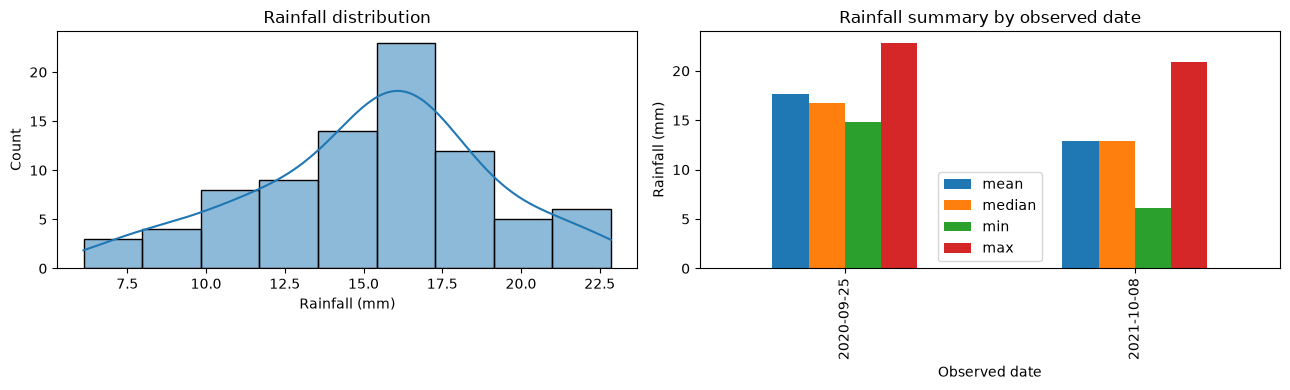

,mean,median,min,max
date,,,,
2020-09-25,17.667686,16.716737,14.830524,22.855469
2021-10-08,12.898695,12.945910,6.110783,20.921135


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["rainfall_mm"], kde=True, ax=axes[0])
axes[0].set_title("Rainfall distribution")
axes[0].set_xlabel("Rainfall (mm)")

date_summary = df.groupby(df["date"].dt.strftime("%Y-%m-%d"))["rainfall_mm"].agg(["mean", "median", "min", "max"])
date_summary.plot(kind="bar", ax=axes[1])
axes[1].set_title("Rainfall summary by observed date")
axes[1].set_ylabel("Rainfall (mm)")
axes[1].set_xlabel("Observed date")
plt.tight_layout()
plt.show()

display(date_summary)


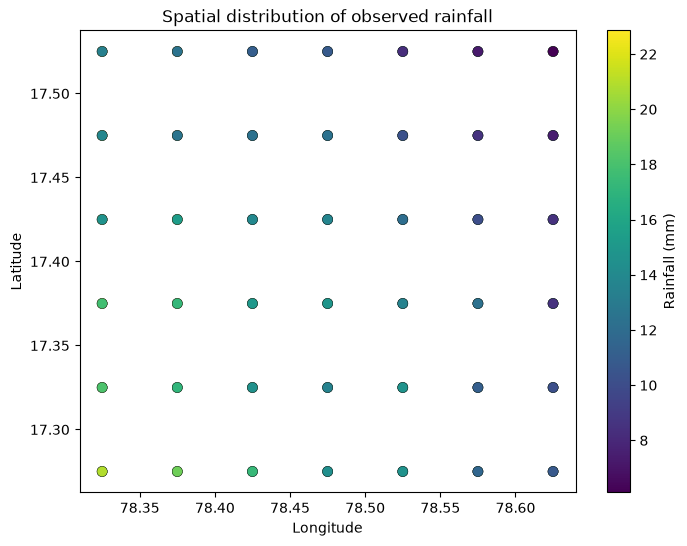

In [5]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    df["longitude"], df["latitude"],
    c=df["rainfall_mm"], cmap="viridis",
    s=55, edgecolor="black", linewidth=0.25
)
plt.colorbar(scatter, label="Rainfall (mm)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Spatial distribution of observed rainfall")
plt.show()


## 5. Prepare features for clustering

In [6]:
cluster_features = ["latitude", "longitude", "rainfall_mm"]
X_cluster = df[cluster_features].copy()

scaler = StandardScaler()
X_cluster_scaled = scaler.fit_transform(X_cluster)

print("Clustering features:", cluster_features)
print("Rows used:", len(X_cluster))


Clustering features: ['latitude', 'longitude', 'rainfall_mm']
Rows used: 84


## 6. Compare K-Means cluster counts

In [7]:
cluster_scores = []

max_k = min(8, len(df) - 1)
for k in range(2, max_k + 1):
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = km.fit_predict(X_cluster_scaled)
    score = silhouette_score(X_cluster_scaled, labels)
    cluster_scores.append({"k": k, "silhouette_score": score, "inertia": km.inertia_})

cluster_comparison = pd.DataFrame(cluster_scores).sort_values("silhouette_score", ascending=False)
display(cluster_comparison)
cluster_comparison.to_csv(OUTPUT_DIR / "rainfall_kmeans_k_comparison.csv", index=False)

best_k = int(cluster_comparison.iloc[0]["k"])
print("Best K by silhouette score:", best_k)


,k,silhouette_score,inertia
4,6,0.347473,57.177706
5,7,0.342776,49.788782
3,5,0.329539,73.003033
6,8,0.327143,44.447124
2,4,0.316743,90.879284
1,3,0.305637,116.054698
0,2,0.300441,161.881994


Best K by silhouette score: 6


## 7. Compare spatial-plus-rainfall clustering with rainfall-only clustering

In [8]:
approaches = {
    "spatial_plus_rainfall": ["latitude", "longitude", "rainfall_mm"],
    "rainfall_only": ["rainfall_mm"]
}

approach_results = []
approach_models = {}

for approach_name, features in approaches.items():
    X = df[features].copy()
    approach_scaler = StandardScaler()
    X_scaled = approach_scaler.fit_transform(X)

    rows = []
    for k in range(2, min(8, len(df) - 1) + 1):
        model = KMeans(n_clusters=k, random_state=42, n_init=20)
        labels = model.fit_predict(X_scaled)
        score = silhouette_score(X_scaled, labels)
        rows.append({"approach": approach_name, "k": k, "silhouette_score": score})

    result = pd.DataFrame(rows)
    approach_results.append(result)
    best_row = result.loc[result["silhouette_score"].idxmax()]
    best_model = KMeans(n_clusters=int(best_row["k"]), random_state=42, n_init=20)
    df[f"{approach_name}_cluster"] = best_model.fit_predict(X_scaled)
    approach_models[approach_name] = {
        "model": best_model,
        "scaler": approach_scaler,
        "features": features,
        "best_k": int(best_row["k"]),
        "silhouette": float(best_row["silhouette_score"])
    }

approach_comparison = pd.concat(approach_results, ignore_index=True)
display(approach_comparison.sort_values(["approach", "silhouette_score"], ascending=[True, False]))
approach_comparison.to_csv(OUTPUT_DIR / "rainfall_clustering_approach_comparison.csv", index=False)

best_approaches = pd.DataFrame([
    {
        "approach": name,
        "best_k": item["best_k"],
        "silhouette_score": item["silhouette"]
    }
    for name, item in approach_models.items()
]).sort_values("silhouette_score", ascending=False)
display(best_approaches)


,approach,k,silhouette_score
7,rainfall_only,2,0.578831
8,rainfall_only,3,0.577569
11,rainfall_only,6,0.572847
13,rainfall_only,8,0.559356
12,rainfall_only,7,0.546661
9,rainfall_only,4,0.540831
10,rainfall_only,5,0.530449
4,spatial_plus_rainfall,6,0.347473
5,spatial_plus_rainfall,7,0.342776
3,spatial_plus_rainfall,5,0.329539


,approach,best_k,silhouette_score
1,rainfall_only,2,0.578831
0,spatial_plus_rainfall,6,0.347473


## 8. Interpret cluster profiles

\nCluster profile: spatial_plus_rainfall_cluster


rainfall_mm                                   \
                                    count       mean        min        max   
spatial_plus_rainfall_cluster                                                
0                                      18  14.022925  10.755352  17.373713   
1                                      20  14.332188  10.119514  16.641756   
2                                       8  21.487428  19.723509  22.855469   
3                                      10   8.701472   6.110783  12.000566   
4                                      19  17.845882  14.516764  20.921135   
5                                       9  16.305080  15.424070  18.223892   

                              latitude                            longitude  \
                                 count       mean     min     max     count   
spatial_plus_rainfall_cluster                                                 
0                                   18  17.475000  17.425  17.525        18   
1                                   20  17.322500  17.275  17.375        20   
2                                    8  17.450000  17.375  17.525         8   
3                                   10  17.465000  17.375  17.525        10   
4                                   19  17.319737  17.275  17.375        19   
5                                    9  17.475000  17.425  17.525         9   

                                                          
                                    mean     min     max  
spatial_plus_rainfall_cluster                             
0                              78.416667  78.325  78.475  
1                              78.557500  78.475  78.625  
2                              78.350000  78.325  78.375  
3                              78.580000  78.525  78.625  
4                              78.393421  78.325  78.475  
5                              78.575000  78.525  78.625

\nCluster profile: rainfall_only_cluster


rainfall_mm                                  latitude  \
                            count       mean        min        max    count   
rainfall_only_cluster                                                         
0                              57  17.326875  14.354228  22.855469       57   
1                              27  10.968747   6.110783  13.917770       27   

                                                 longitude                     \
                            mean     min     max     count       mean     min   
rainfall_only_cluster                                                           
0                      17.382895  17.275  17.525        57  78.456579  78.325   
1                      17.436111  17.275  17.525        27  78.513889  78.325   

                               
                          max  
rainfall_only_cluster          
0                      78.625  
1                      78.625

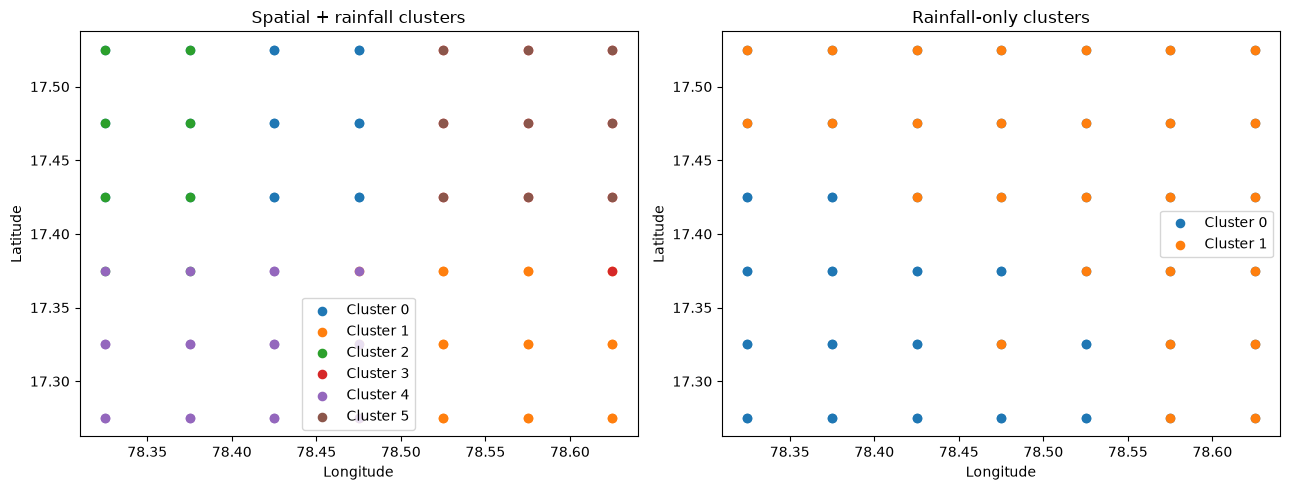

In [9]:
profile_columns = ["rainfall_mm", "latitude", "longitude"]
for cluster_col in ["spatial_plus_rainfall_cluster", "rainfall_only_cluster"]:
    print(f"\\nCluster profile: {cluster_col}")
    profile = df.groupby(cluster_col)[profile_columns].agg(["count", "mean", "min", "max"])
    display(profile)
    profile.to_csv(OUTPUT_DIR / f"{cluster_col}_profile.csv")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, cluster_col, title in [
    (axes[0], "spatial_plus_rainfall_cluster", "Spatial + rainfall clusters"),
    (axes[1], "rainfall_only_cluster", "Rainfall-only clusters")
]:
    for cluster_id, part in df.groupby(cluster_col):
        ax.scatter(part["longitude"], part["latitude"], label=f"Cluster {cluster_id}", s=35)
    ax.set_title(title)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.legend()
plt.tight_layout()
plt.show()


## 9. Spatial rainfall regression — evaluate each date separately

The target is the **measured rainfall in millimetres**. Predictors are latitude and longitude only. Models are evaluated separately for each observed date, using spatial groups so nearby repeated observations are not randomly split across folds.

This tests whether a model can estimate rainfall at held-out sampling locations for that same date. It does **not** test future-date forecasting.


In [10]:
regression_algorithms = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "KNN Regressor": KNeighborsRegressor(n_neighbors=5, weights="distance"),
    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=300, min_samples_leaf=2, random_state=42, n_jobs=-1
    ),
    "Extra Trees Regressor": ExtraTreesRegressor(
        n_estimators=300, min_samples_leaf=2, random_state=42, n_jobs=-1
    ),
    "Gradient Boosting Regressor": GradientBoostingRegressor(random_state=42),
    "SVR": SVR(C=10, epsilon=0.1)
}

# Group identical sampling coordinates together, preventing coordinate leakage.
df["location_group"] = (
    df["latitude"].round(5).astype(str) + "_" + df["longitude"].round(5).astype(str)
)

spatial_cv_rows = []
best_models_by_date = {}

for observed_date, date_df in df.groupby("date"):
    date_df = date_df.reset_index(drop=True)
    X = date_df[["latitude", "longitude"]]
    y = date_df["rainfall_mm"]
    groups = date_df["location_group"]

    n_groups = groups.nunique()
    n_splits = min(5, n_groups)
    if len(date_df) < 10 or n_splits < 2:
        print(f"Skipping {observed_date.date()}: not enough independent locations.")
        continue

    cv = GroupKFold(n_splits=n_splits)
    date_results = []

    baseline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DummyRegressor(strategy="mean"))
    ])
    baseline_scores = -cross_val_score(
        baseline, X, y, groups=groups, cv=cv,
        scoring="neg_mean_absolute_error", n_jobs=-1
    )
    spatial_cv_rows.append({
        "date": observed_date.strftime("%Y-%m-%d"),
        "algorithm": "Dummy Mean Baseline",
        "spatial_cv_mae_mm": baseline_scores.mean(),
        "spatial_cv_mae_std": baseline_scores.std()
    })

    for algorithm_name, algorithm in regression_algorithms.items():
        steps = [("imputer", SimpleImputer(strategy="median"))]
        if algorithm_name in ["KNN Regressor", "SVR", "Ridge Regression", "Linear Regression"]:
            steps.append(("scaler", StandardScaler()))
        steps.append(("model", algorithm))
        pipeline = Pipeline(steps)

        scores = -cross_val_score(
            pipeline, X, y, groups=groups, cv=cv,
            scoring="neg_mean_absolute_error", n_jobs=-1
        )
        row = {
            "date": observed_date.strftime("%Y-%m-%d"),
            "algorithm": algorithm_name,
            "spatial_cv_mae_mm": scores.mean(),
            "spatial_cv_mae_std": scores.std()
        }
        spatial_cv_rows.append(row)
        date_results.append(row)

    date_result_df = pd.DataFrame(date_results).sort_values("spatial_cv_mae_mm")
    best_name = date_result_df.iloc[0]["algorithm"]
    best_model = regression_algorithms[best_name]

    best_steps = [("imputer", SimpleImputer(strategy="median"))]
    if best_name in ["KNN Regressor", "SVR", "Ridge Regression", "Linear Regression"]:
        best_steps.append(("scaler", StandardScaler()))
    best_steps.append(("model", best_model))
    best_pipeline = Pipeline(best_steps)
    best_pipeline.fit(X, y)

    best_models_by_date[observed_date.strftime("%Y-%m-%d")] = {
        "algorithm": best_name,
        "pipeline": best_pipeline,
        "cv_mae": float(date_result_df.iloc[0]["spatial_cv_mae_mm"])
    }

spatial_cv_results = pd.DataFrame(spatial_cv_rows)
display(spatial_cv_results.sort_values(["date", "spatial_cv_mae_mm"]))
spatial_cv_results.to_csv(OUTPUT_DIR / "rainfall_spatial_regression_cv_results.csv", index=False)


,date,algorithm,spatial_cv_mae_mm,spatial_cv_mae_std
7,2020-09-25,SVR,0.615981,0.102643
6,2020-09-25,Gradient Boosting Regressor,0.620748,0.100763
3,2020-09-25,KNN Regressor,0.630512,0.060373
4,2020-09-25,Random Forest Regressor,0.737360,0.119754
5,2020-09-25,Extra Trees Regressor,0.805775,0.155638
2,2020-09-25,Ridge Regression,1.075030,0.148895
1,2020-09-25,Linear Regression,1.076683,0.148867
0,2020-09-25,Dummy Mean Baseline,1.848846,0.185326
14,2021-10-08,Gradient Boosting Regressor,0.697664,0.179581
9,2021-10-08,Linear Regression,0.779676,0.164268


## 10. Select the best algorithm per date

In [11]:
selection_rows = []
for date_text, item in best_models_by_date.items():
    baseline_row = spatial_cv_results[
        (spatial_cv_results["date"] == date_text)
        & (spatial_cv_results["algorithm"] == "Dummy Mean Baseline")
    ]
    baseline_mae = float(baseline_row["spatial_cv_mae_mm"].iloc[0]) if not baseline_row.empty else np.nan

    selection_rows.append({
        "date": date_text,
        "best_algorithm": item["algorithm"],
        "best_spatial_cv_mae_mm": item["cv_mae"],
        "dummy_baseline_spatial_cv_mae_mm": baseline_mae,
        "beats_dummy_baseline": bool(item["cv_mae"] < baseline_mae) if pd.notna(baseline_mae) else False
    })

selection_df = pd.DataFrame(selection_rows)
display(selection_df)
selection_df.to_csv(OUTPUT_DIR / "rainfall_best_algorithm_by_date.csv", index=False)


,date,best_algorithm,best_spatial_cv_mae_mm,dummy_baseline_spatial_cv_mae_mm,beats_dummy_baseline
0,2020-09-25,SVR,0.615981,1.848846,True
1,2021-10-08,Gradient Boosting Regressor,0.697664,2.681354,True


## 11. Save candidate models only when they beat the baseline

These are **date-specific spatial interpolation candidates**, not flood-risk models or rainfall forecasting models. Saving is conditional on the selected algorithm beating the dummy mean baseline in spatial cross-validation.


In [12]:
saved_models = []

for date_text, item in best_models_by_date.items():
    row = selection_df[selection_df["date"] == date_text].iloc[0]
    if not row["beats_dummy_baseline"]:
        print(f"Not saving {date_text}: selected model did not beat the dummy baseline.")
        continue

    safe_date = date_text.replace("-", "")
    model_path = MODEL_DIR / f"rainfall_spatial_interpolation_{safe_date}.joblib"
    metadata_path = MODEL_DIR / f"rainfall_spatial_interpolation_{safe_date}_metadata.json"

    joblib.dump(item["pipeline"], model_path)
    metadata = {
        "dataset": "Hyderabad rainfall observations",
        "dataset_file": str(DATA_PATH),
        "observed_date": date_text,
        "target": "rainfall_mm",
        "features": ["latitude", "longitude"],
        "algorithm": item["algorithm"],
        "spatial_cv_mae_mm": item["cv_mae"],
        "model_type": "date-specific spatial interpolation candidate",
        "not_a_forecast": True,
        "not_a_flood_risk_classifier": True,
        "deployment_approval": "pending scientific and integration review"
    }
    metadata_path.write_text(json.dumps(metadata, indent=4), encoding="utf-8")
    saved_models.append(str(model_path))
    print("Saved:", model_path)

print("\\nSaved candidate models:", len(saved_models))


Saved: C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\models\flood\rainfall\rainfall_spatial_interpolation_20200925.joblib
Saved: C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\models\flood\rainfall\rainfall_spatial_interpolation_20211008.joblib
\nSaved candidate models: 2


## 12. Final findings and interpretation

In [13]:
print("FINAL RAINFALL DATASET SUMMARY")
print("------------------------------")
print("Clean observations:", len(df))
print("Observed dates:", df["date"].nunique())
print("Unique sampling locations:", df[["latitude", "longitude"]].drop_duplicates().shape[0])
print("Rainfall range (mm):", round(df["rainfall_mm"].min(), 3), "to", round(df["rainfall_mm"].max(), 3))

print("\\nClustering comparison:")
display(best_approaches)

print("\\nSpatial regression model selection:")
display(selection_df)

print("\\nInterpretation:")
print("1. Clusters summarize observed rainfall patterns; they are not verified flood-risk labels.")
print("2. The dataset contains only two dates, so it cannot support reliable temporal forecasting.")
print("3. Spatial regression is evaluated separately for each observed date and estimates rainfall at held-out locations.")
print("4. No flood/no-flood classification target is created from this rainfall dataset.")
print("5. Candidate models require further scientific review before integration into the shared FastAPI application.")
print("\\nExperiment outputs saved in:", OUTPUT_DIR)


FINAL RAINFALL DATASET SUMMARY
------------------------------
Clean observations: 84
Observed dates: 2
Unique sampling locations: 42
Rainfall range (mm): 6.111 to 22.855
\nClustering comparison:


,approach,best_k,silhouette_score
1,rainfall_only,2,0.578831
0,spatial_plus_rainfall,6,0.347473


\nSpatial regression model selection:


,date,best_algorithm,best_spatial_cv_mae_mm,dummy_baseline_spatial_cv_mae_mm,beats_dummy_baseline
0,2020-09-25,SVR,0.615981,1.848846,True
1,2021-10-08,Gradient Boosting Regressor,0.697664,2.681354,True


\nInterpretation:
1. Clusters summarize observed rainfall patterns; they are not verified flood-risk labels.
2. The dataset contains only two dates, so it cannot support reliable temporal forecasting.
3. Spatial regression is evaluated separately for each observed date and estimates rainfall at held-out locations.
4. No flood/no-flood classification target is created from this rainfall dataset.
5. Candidate models require further scientific review before integration into the shared FastAPI application.
\nExperiment outputs saved in: C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\flood\rainfall_experiments


## 13. Files produced

The notebook writes the following experiment outputs under `data/processed/flood/rainfall_experiments/`:
- `rainfall_kmeans_k_comparison.csv`
- `rainfall_clustering_approach_comparison.csv`
- Cluster profile CSV files
- `rainfall_spatial_regression_cv_results.csv`
- `rainfall_best_algorithm_by_date.csv`

If a date-specific spatial regression model beats the dummy baseline, its `.joblib` file and metadata are saved under `models/flood/rainfall/`.

**Do not describe these outputs as flood predictions.** This dataset contains rainfall measurements only.


In [14]:
display(
    spatial_cv_results[
        spatial_cv_results["date"] == "2021-10-08"
    ]
)

,date,algorithm,spatial_cv_mae_mm,spatial_cv_mae_std
8,2021-10-08,Dummy Mean Baseline,2.681354,0.314358
9,2021-10-08,Linear Regression,0.779676,0.164268
10,2021-10-08,Ridge Regression,0.785507,0.179882
11,2021-10-08,KNN Regressor,0.841332,0.288349
12,2021-10-08,Random Forest Regressor,0.888085,0.251818
13,2021-10-08,Extra Trees Regressor,0.905937,0.299330
14,2021-10-08,Gradient Boosting Regressor,0.697664,0.179581
15,2021-10-08,SVR,0.850174,0.146782
